# 02 - MLP Classifier

Implementation of a Multi-Layer Perceptron (MLP) as a baseline classification model using the Fashion-MNIST dataset.

In [18]:
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

In [19]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATASET_DIR = PROJECT_DIR / "data" / "fashion_mnist"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(PROJECT_DIR / "config.json", "r") as file:
    CONFIG = json.load(file)

GENERAL_CONFIG = CONFIG["general"]
MLP_CONFIG = CONFIG["models"]["mlp"]

RANDOM_SEED = GENERAL_CONFIG["random_seed"]

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

if GENERAL_CONFIG["device"] == "auto":
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
else:
    device = torch.device(GENERAL_CONFIG["device"])

print("Project directory:", PROJECT_DIR)
print("Available device:", device)
print("Random seed:", RANDOM_SEED)

Project directory: d:\generative-models-comparison
Available device: cpu
Random seed: 42


In [20]:
print("MLP Configuration:")
for key, value in MLP_CONFIG.items():
    print(f"{key}: {value}")

MLP Configuration:
architecture: [784, 256, 64, 10]
hidden_activation: ReLU
output_activation: None
inference_activation: Softmax
dropout: 0.3
optimizer: Adam
learning_rate: 0.001
weight_decay: 0.0001
loss: CrossEntropyLoss
epochs: 30
early_stopping_patience: 5


In [21]:
# Load prepared dataset
dataset_path = DATASET_DIR / "fashion_mnist_splits.pt"

dataset = torch.load(
    dataset_path,
    map_location="cpu",
    weights_only=True
)

# Extract training data
train_images = dataset["train_images"]
train_labels = dataset["train_labels"]

# Extract validation data
val_images = dataset["val_images"]
val_labels = dataset["val_labels"]

# Extract testing data
test_images = dataset["test_images"]
test_labels = dataset["test_labels"]

# Display dataset shapes
print("Train images:", train_images.shape)
print("Train labels:", train_labels.shape)

print("Validation images:", val_images.shape)
print("Validation labels:", val_labels.shape)

print("Test images:", test_images.shape)
print("Test labels:", test_labels.shape)

Train images: torch.Size([56000, 1, 28, 28])
Train labels: torch.Size([56000])
Validation images: torch.Size([7000, 1, 28, 28])
Validation labels: torch.Size([7000])
Test images: torch.Size([7000, 1, 28, 28])
Test labels: torch.Size([7000])


Preprocessing

In [22]:
# Normalize and flatten images
train_images = train_images.float().view(-1, 784) / 255.0
val_images = val_images.float().view(-1, 784) / 255.0
test_images = test_images.float().view(-1, 784) / 255.0

# Convert labels to long data type
train_labels = train_labels.long()
val_labels = val_labels.long()
test_labels = test_labels.long()

# Display preprocessing results
print("Train shape:", train_images.shape)
print("Validation shape:", val_images.shape)
print("Test shape:", test_images.shape)

print("Pixel range:", train_images.min().item(), "-", train_images.max().item())

Train shape: torch.Size([56000, 784])
Validation shape: torch.Size([7000, 784])
Test shape: torch.Size([7000, 784])
Pixel range: 0.0 - 1.0


In [23]:
# Get batch size from configuration
BATCH_SIZE = GENERAL_CONFIG["batch_size"]

# Create TensorDataset
train_dataset = TensorDataset(train_images, train_labels)
val_dataset = TensorDataset(val_images, val_labels)
test_dataset = TensorDataset(test_images, test_labels)

# Create DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Display DataLoader information
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Batch size: 128
Training batches: 438
Validation batches: 55
Testing batches: 55


In [24]:
class MLPClassifier(nn.Module):
    def __init__(self, config):
        super(MLPClassifier, self).__init__()

        architecture = config["architecture"]
        dropout_rate = config["dropout"]

        layers = []

        for i in range(len(architecture) - 2):
            layers.append(
                nn.Linear(architecture[i], architecture[i + 1])
            )
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_rate))

        layers.append(
            nn.Linear(architecture[-2], architecture[-1])
        )

        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)


model = MLPClassifier(MLP_CONFIG).to(device)

print(model)

MLPClassifier(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [25]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=MLP_CONFIG["learning_rate"],
    weight_decay=MLP_CONFIG["weight_decay"]
)

EPOCHS = MLP_CONFIG["epochs"]
PATIENCE = MLP_CONFIG["early_stopping_patience"]

print("Loss Function:", criterion)
print("Optimizer:", optimizer)
print("Learning Rate:", MLP_CONFIG["learning_rate"])
print("Weight Decay:", MLP_CONFIG["weight_decay"])
print("Epochs:", EPOCHS)
print("Early Stopping Patience:", PATIENCE)

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Learning Rate: 0.001
Weight Decay: 0.0001
Epochs: 30
Early Stopping Patience: 5


In [26]:
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

for epoch in range(EPOCHS):

    # Training
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total

    # Validation
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total

    # Save training history
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    # Early Stopping
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Acc: {epoch_train_acc:.4f} "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Acc: {epoch_val_acc:.4f}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch + 1}.")
        break

# Restore best model
if best_model_state is not None:
    model.load_state_dict(best_model_state)

print(f"\nBest Validation Loss: {best_val_loss:.4f}")
print(f"Total Epochs Trained: {len(train_losses)}") 

Epoch [1/30] Train Loss: 0.7048 Train Acc: 0.7495 Val Loss: 0.4540 Val Acc: 0.8340
Epoch [2/30] Train Loss: 0.4636 Train Acc: 0.8347 Val Loss: 0.4044 Val Acc: 0.8510
Epoch [3/30] Train Loss: 0.4224 Train Acc: 0.8510 Val Loss: 0.3935 Val Acc: 0.8534
Epoch [4/30] Train Loss: 0.3955 Train Acc: 0.8580 Val Loss: 0.3644 Val Acc: 0.8657
Epoch [5/30] Train Loss: 0.3784 Train Acc: 0.8638 Val Loss: 0.3514 Val Acc: 0.8720
Epoch [6/30] Train Loss: 0.3668 Train Acc: 0.8681 Val Loss: 0.3569 Val Acc: 0.8691
Epoch [7/30] Train Loss: 0.3580 Train Acc: 0.8693 Val Loss: 0.3335 Val Acc: 0.8780
Epoch [8/30] Train Loss: 0.3484 Train Acc: 0.8739 Val Loss: 0.3317 Val Acc: 0.8790
Epoch [9/30] Train Loss: 0.3397 Train Acc: 0.8768 Val Loss: 0.3300 Val Acc: 0.8809
Epoch [10/30] Train Loss: 0.3344 Train Acc: 0.8789 Val Loss: 0.3279 Val Acc: 0.8790
Epoch [11/30] Train Loss: 0.3273 Train Acc: 0.8812 Val Loss: 0.3221 Val Acc: 0.8800
Epoch [12/30] Train Loss: 0.3256 Train Acc: 0.8817 Val Loss: 0.3214 Val Acc: 0.8834
E

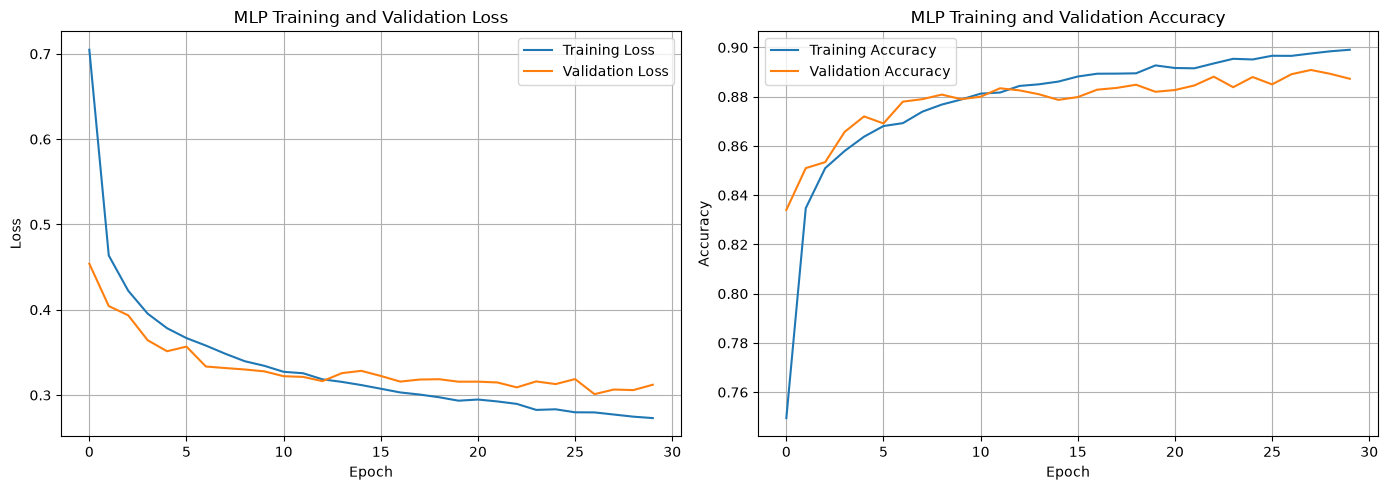

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss Curve
axes[0].plot(train_losses, label="Training Loss")
axes[0].plot(val_losses, label="Validation Loss")
axes[0].set_title("MLP Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy Curve
axes[1].plot(train_accuracies, label="Training Accuracy")
axes[1].plot(val_accuracies, label="Validation Accuracy")
axes[1].set_title("MLP Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "mlp_training_curves.png",
    dpi=100,
    bbox_inches="tight"
)
plt.show()

In [29]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

In [30]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model.eval()

test_predictions = []
test_targets = []
test_running_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        test_predictions.extend(predicted.cpu().numpy())
        test_targets.extend(labels.cpu().numpy())

test_loss = test_running_loss / len(test_loader.dataset)
test_accuracy = accuracy_score(
    test_targets,
    test_predictions
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        test_targets,
        test_predictions,
        target_names=class_names
    )
)

Test Loss: 0.2980
Test Accuracy: 0.8950

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.81      0.90      0.85       700
     Trouser       0.99      0.98      0.98       700
    Pullover       0.84      0.83      0.84       700
       Dress       0.87      0.91      0.89       700
        Coat       0.82      0.83      0.82       700
      Sandal       0.97      0.96      0.96       700
       Shirt       0.75      0.64      0.69       700
     Sneaker       0.95      0.98      0.96       700
         Bag       0.97      0.97      0.97       700
  Ankle boot       0.98      0.96      0.97       700

    accuracy                           0.90      7000
   macro avg       0.89      0.89      0.89      7000
weighted avg       0.89      0.90      0.89      7000



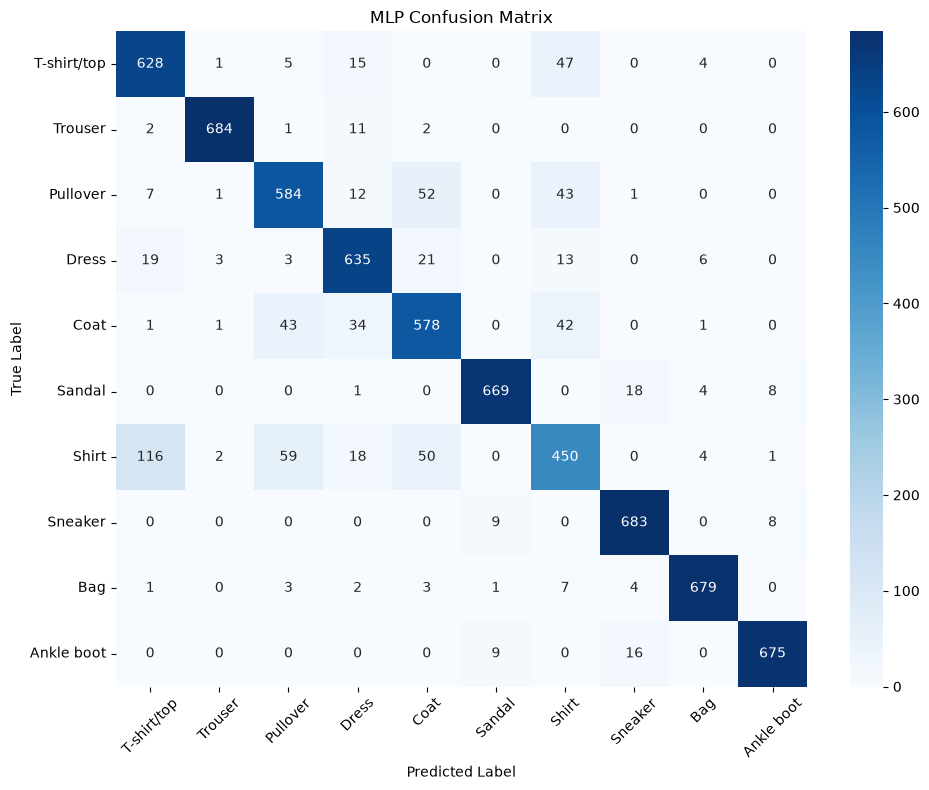

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    test_targets,
    test_predictions
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MLP Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "mlp_confusion_matrix.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()

In [32]:
# Select one test image
images, labels = next(iter(test_loader))

sample_image = images[0].unsqueeze(0).to(device)
true_label = labels[0].item()

# Classification prediction
model.eval()

with torch.no_grad():
    logits = model(sample_image)
    probabilities = torch.softmax(logits, dim=1)

predicted_label = torch.argmax(probabilities, dim=1).item()

# Display output dimensions
print("Input Image Shape:", sample_image.shape)
print("MLP Output Shape:", logits.shape)
print("Expected Image Output Shape: (1, 1, 28, 28)")
print("True Label:", class_names[true_label])
print("Predicted Label:", class_names[predicted_label])

Input Image Shape: torch.Size([1, 784])
MLP Output Shape: torch.Size([1, 10])
Expected Image Output Shape: (1, 1, 28, 28)
True Label: Dress
Predicted Label: Dress


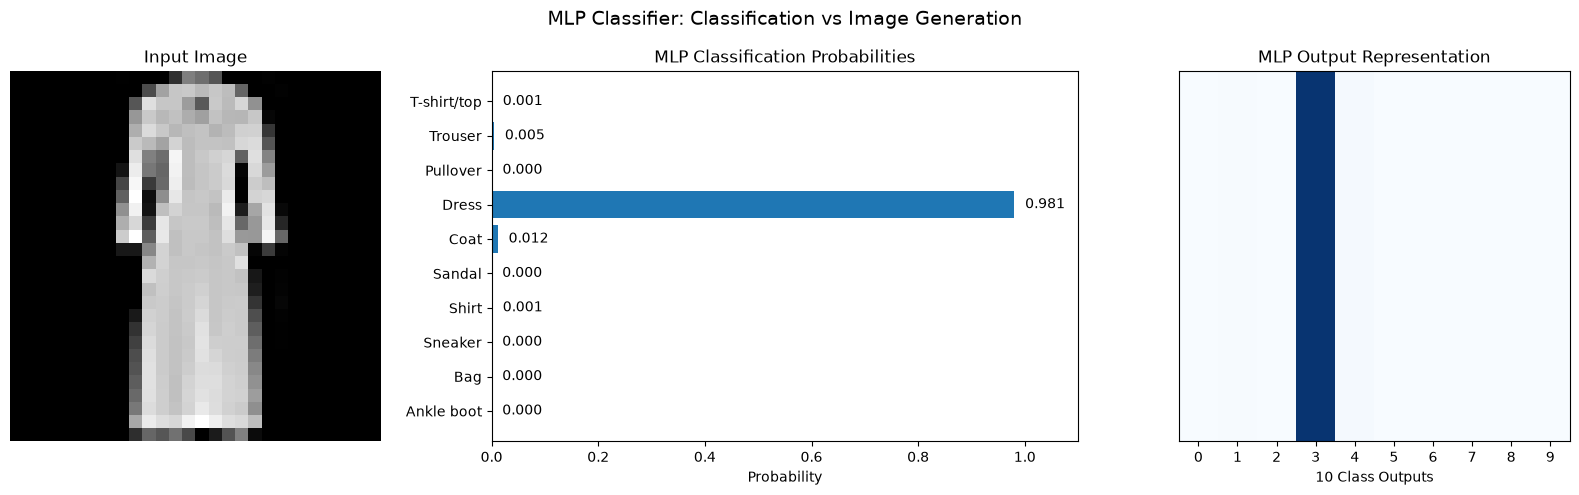

MLP Output: (1, 10)
Required Image Output: (1, 1, 28, 28)
Number of MLP outputs: 10
Number of image pixels: 784


In [35]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    gridspec_kw={"width_ratios": [1, 1.5, 1]}
)

# 1. Input Image
display_image = sample_image.reshape(28, 28).cpu().numpy()

axes[0].imshow(display_image, cmap="gray")
axes[0].set_title("Input Image")
axes[0].axis("off")

# 2. Classification Probabilities
probs = probabilities.cpu().squeeze().numpy()

axes[1].barh(class_names, probs)
axes[1].set_title("MLP Classification Probabilities")
axes[1].set_xlabel("Probability")
axes[1].set_xlim(0, 1.1)
axes[1].invert_yaxis()

for i, probability in enumerate(probs):
    axes[1].text(
        probability + 0.02,
        i,
        f"{probability:.3f}",
        va="center"
    )

# 3. Output Representation
axes[2].imshow(
    probs.reshape(1, -1),
    cmap="Blues",
    aspect="auto",
    vmin=0,
    vmax=1
)

axes[2].set_title("MLP Output Representation")
axes[2].set_xlabel("10 Class Outputs")
axes[2].set_yticks([])
axes[2].set_xticks(range(10))
axes[2].set_xticklabels(range(10))

plt.suptitle(
    "MLP Classifier: Classification vs Image Generation",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "mlp_generation_limitation.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("MLP Output:", tuple(logits.shape))
print("Required Image Output: (1, 1, 28, 28)")
print("Number of MLP outputs:", logits.shape[1])
print("Number of image pixels:", 28 * 28)